<a href="https://colab.research.google.com/github/kananshr13/CSET-343-Ai-in-Healthcare/blob/main/Lab_Experiment_9_CSET_343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q opencv-python tensorflow scikit-learn matplotlib seaborn kagglehub

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import tensorflow as tf

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
path = kagglehub.dataset_download(
    "shahliza27/ur-fall-detection-dataset"
)

print("Dataset location:", path)

100%|██████████| 4.18G/4.18G [00:55<00:00, 80.4MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/shahliza27/ur-fall-detection-dataset/versions/1


In [4]:
for current_path, folders, files in os.walk(path):

    if files:
        print("Directory:", os.path.basename(current_path))
        print("Images available:", len(files))
        print("Sample:", files[:3])
        print("-" * 40)

Directory: adl-20-cam0-rgb
Images available: 270
Sample: ['adl-20-cam0-rgb-017.png', 'adl-20-cam0-rgb-249.png', 'adl-20-cam0-rgb-162.png']
----------------------------------------
Directory: adl-24-cam0-rgb
Images available: 70
Sample: ['adl-24-cam0-rgb-010.png', 'adl-24-cam0-rgb-050.png', 'adl-24-cam0-rgb-019.png']
----------------------------------------
Directory: fall-15-cam0-rgb
Images available: 71
Sample: ['fall-15-cam0-rgb-022.png', 'fall-15-cam0-rgb-058.png', 'fall-15-cam0-rgb-028.png']
----------------------------------------
Directory: adl-32-cam0-rgb
Images available: 200
Sample: ['adl-32-cam0-rgb-090.png', 'adl-32-cam0-rgb-093.png', 'adl-32-cam0-rgb-104.png']
----------------------------------------
Directory: adl-04-cam0-rgb
Images available: 150
Sample: ['adl-04-cam0-rgb-053.png', 'adl-04-cam0-rgb-047.png', 'adl-04-cam0-rgb-086.png']
----------------------------------------
Directory: adl-10-cam0-rgb
Images available: 300
Sample: ['adl-10-cam0-rgb-083.png', 'adl-10-cam0-

In [5]:
image_sequences = []
sequence_labels = []

for current_path, folders, files in os.walk(path):

    images = [f for f in files if f.lower().endswith(".png")]

    if not images:
        continue

    folder = os.path.basename(current_path).lower()

    if folder.startswith("fall-"):
        class_id = 1

    elif folder.startswith("adl-"):
        class_id = 0

    else:
        continue

    image_sequences.append(current_path)
    sequence_labels.append(class_id)

print("Total sequences:", len(image_sequences))
print("Label distribution:", Counter(sequence_labels))

Total sequences: 70
Label distribution: Counter({0: 40, 1: 30})


In [6]:
IMAGE_DIM = 112
FRAME_COUNT = 16

def load_video_frames(sequence_folder):

    filenames = sorted([
        name for name in os.listdir(sequence_folder)
        if name.lower().endswith(".png")
    ])

    if len(filenames) == 0:
        return None

    selected_frames = np.linspace(
        0,
        len(filenames) - 1,
        FRAME_COUNT,
        dtype=int
    )

    video_data = []

    for frame_number in selected_frames:

        file_location = os.path.join(
            sequence_folder,
            filenames[frame_number]
        )

        image = cv2.imread(file_location)

        if image is None:
            return None

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = cv2.resize(
            image,
            (IMAGE_DIM, IMAGE_DIM)
        )

        image = image.astype("float32") / 255.0

        video_data.append(image)

    return np.asarray(video_data, dtype=np.float32)

Feature dimensions: (70, 16, 112, 112, 3)
Target dimensions: (70,)


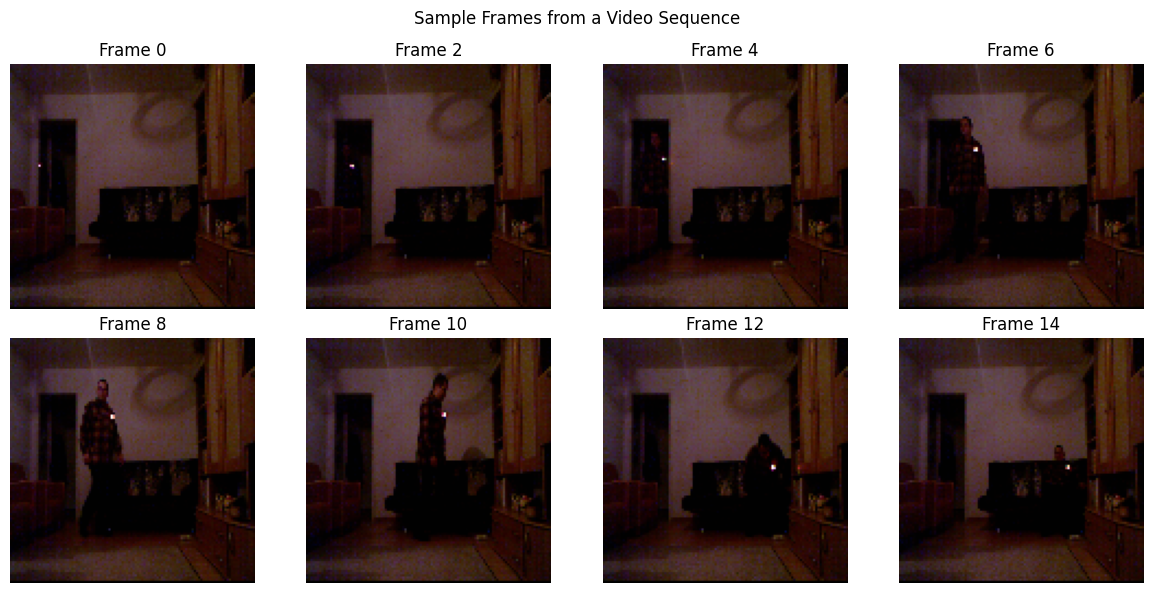

Classes: Counter({np.int32(0): 40, np.int32(1): 30})


In [8]:
features = []
targets = []

for folder, label in zip(image_sequences, sequence_labels):

    frames = load_video_frames(folder)

    if frames is not None:
        features.append(frames)
        targets.append(label)

X = np.asarray(features, dtype=np.float32)
y = np.asarray(targets, dtype=np.int32)

print("Feature dimensions:", X.shape)
print("Target dimensions:", y.shape)

plt.figure(figsize=(12, 6))

for index in range(8):

    plt.subplot(2, 4, index + 1)

    plt.imshow(X[0][index * 2])

    plt.title("Frame " + str(index * 2))
    plt.axis("off")

plt.suptitle("Sample Frames from a Video Sequence")
plt.tight_layout()
plt.show()
print("Classes:", Counter(y))

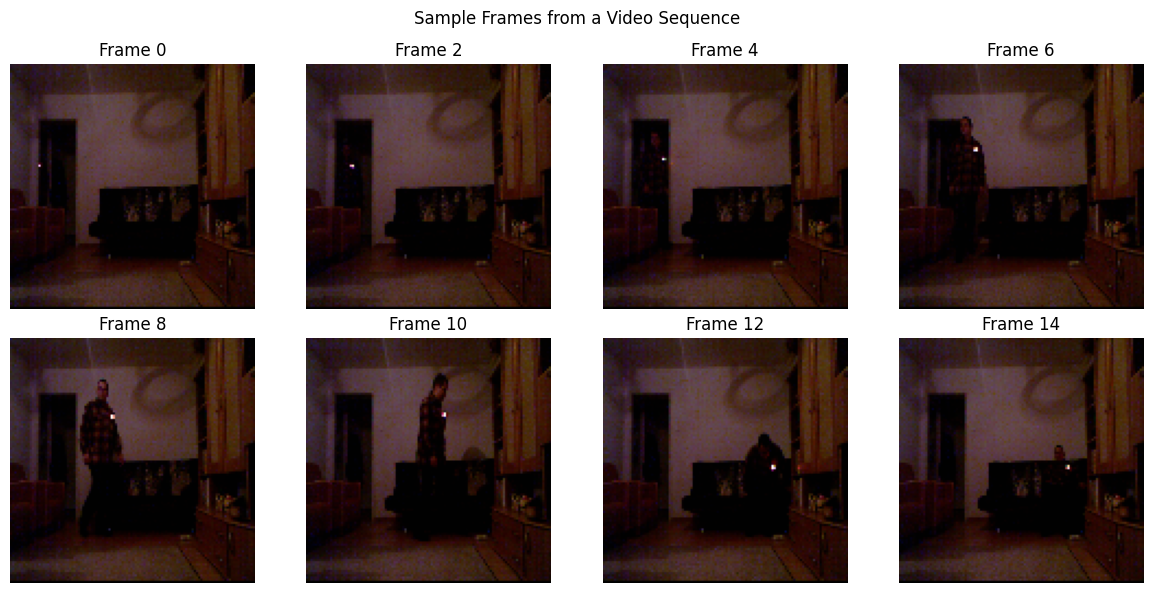

In [9]:
plt.figure(figsize=(12, 6))

for index in range(8):

    plt.subplot(2, 4, index + 1)

    plt.imshow(X[0][index * 2])

    plt.title("Frame " + str(index * 2))
    plt.axis("off")

plt.suptitle("Sample Frames from a Video Sequence")
plt.tight_layout()
plt.show()

In [10]:
X_train, X_remaining, y_train, y_remaining = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining
)

print("Training samples:", X_train.shape)
print("Validation samples:", X_val.shape)
print("Testing samples:", X_test.shape)

Training samples: (49, 16, 112, 112, 3)
Validation samples: (10, 16, 112, 112, 3)
Testing samples: (11, 16, 112, 112, 3)


In [11]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv3D,
    MaxPooling3D,
    BatchNormalization,
    GlobalAveragePooling3D,
    Dense,
    Dropout
)

fall_model = Sequential([

    Input(shape=(16, 112, 112, 3)),

    Conv3D(16, kernel_size=3, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling3D(pool_size=(1, 2, 2)),

    Conv3D(32, kernel_size=3, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    Conv3D(64, kernel_size=3, activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling3D(pool_size=(2, 2, 2)),

    GlobalAveragePooling3D(),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

fall_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

fall_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 112, 112,   │            64 │
│ (BatchNormalization)            │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 56, 56, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 28, 28, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,201 (293.75 KB)

 Trainable params: 74,977 (292.88 KB)

 Non-trainable params: 224 (896.00 B)

In [12]:
unique_labels = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=unique_labels,
    y=y_train
)

weight_dictionary = dict(zip(unique_labels, weights))

print("Calculated weights:", weight_dictionary)

Calculated weights: {np.int32(0): np.float64(0.875), np.int32(1): np.float64(1.1666666666666667)}


In [14]:
from tensorflow.keras.callbacks import EarlyStopping

stop_training = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

training_history = fall_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=2,
    class_weight=weight_dictionary,
    callbacks=[stop_training],
    verbose=1
)

Epoch 1/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.6327 - loss: 0.6651 - val_accuracy: 0.4000 - val_loss: 0.7187
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 47s 2s/step - accuracy: 0.7143 - loss: 0.5657 - val_accuracy: 0.7000 - val_loss: 0.6281
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.6735 - loss: 0.5519 - val_accuracy: 0.6000 - val_loss: 0.6221
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.7143 - loss: 0.5569 - val_accuracy: 0.7000 - val_loss: 0.6393
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - accuracy: 0.5918 - loss: 0.5708 - val_accuracy: 0.7000 - val_loss: 0.7547


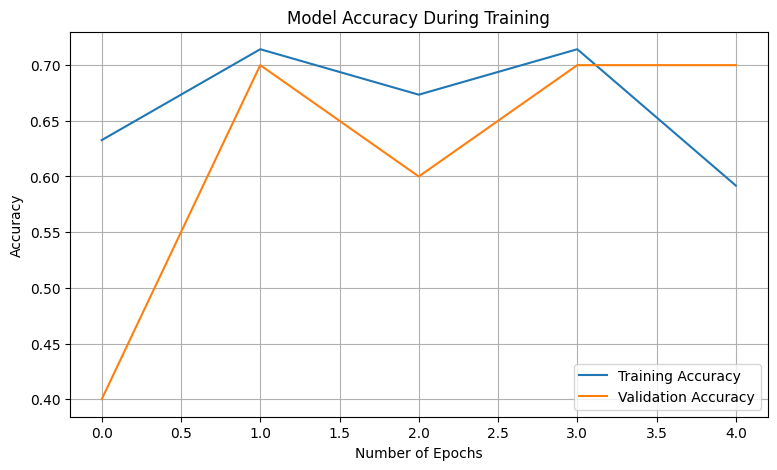

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    training_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    training_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy During Training")

plt.legend()
plt.grid(True)
plt.show()

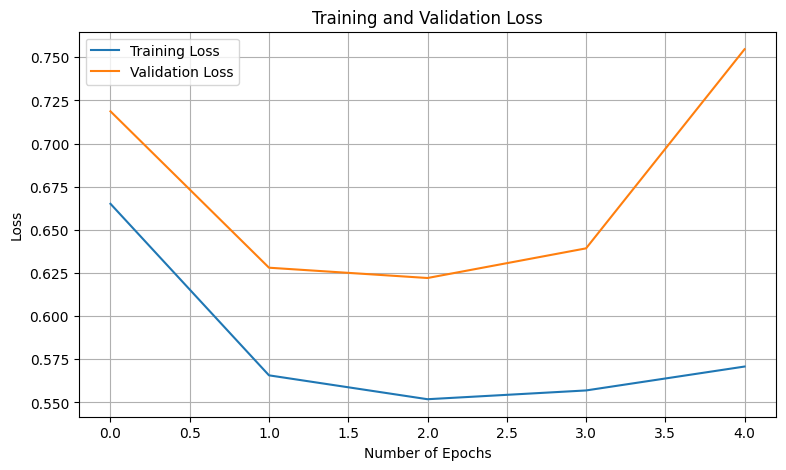

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    training_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    training_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Number of Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
probabilities = fall_model.predict(X_test).flatten()

predictions = (probabilities >= 0.5).astype(int)

print("Accuracy:",
      accuracy_score(y_test, predictions))

print("Precision:",
      precision_score(y_test, predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, predictions, zero_division=0))

if len(np.unique(y_test)) == 2:
    print("ROC-AUC:",
          roc_auc_score(y_test, probabilities))

print("\nDetailed Classification Report:\n")

print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Non-Fall", "Fall"],
    zero_division=0
))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Accuracy: 0.5454545454545454
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 1.0

Detailed Classification Report:

              precision    recall  f1-score   support

    Non-Fall       0.55      1.00      0.71         6
        Fall       0.00      0.00      0.00         5

    accuracy                           0.55        11
   macro avg       0.27      0.50      0.35        11
weighted avg       0.30      0.55      0.39        11



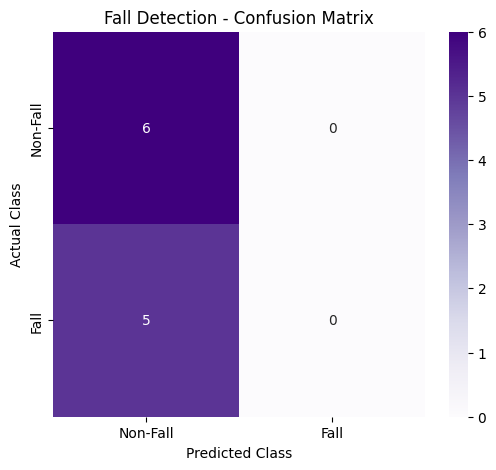

In [18]:
matrix = confusion_matrix(
    y_test,
    predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Non-Fall", "Fall"],
    yticklabels=["Non-Fall", "Fall"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Fall Detection - Confusion Matrix")

plt.show()